# Prescriptive layer — what the model recommends

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(arrow)
  library(tidyverse)
  library(ggthemes)
  library(gt)
  library(IRdisplay)
}))

options(repr.plot.width = 14, repr.plot.height = 6, repr.plot.res = 150)

ROOT  <- if (dir.exists(file.path(getwd(), "data"))) getwd() else dirname(getwd())
DATA  <- file.path(ROOT, "data")
PLOTS <- file.path(ROOT, "results", "plots", "playbook")
dir.create(PLOTS, recursive = TRUE, showWarnings = FALSE)

FT_THEME <- theme_fivethirtyeight() +
  theme(axis.title        = element_text(),
        axis.text         = element_text(size = 10),
        panel.background  = element_rect(fill = "white", color = NA),
        plot.background   = element_rect(fill = "white", color = NA),
        legend.background = element_rect(fill = "white", color = NA),
        strip.text        = element_text(size = 12, face = "bold"),
        plot.title        = element_text(size = 16, face = "bold"))

plot_path <- function(name) file.path(PLOTS, name)

pb  <- read_parquet(file.path(DATA, "adjustability_playbook.parquet"))
val <- read_parquet(file.path(DATA, "adjustability_value.parquet"),
                    col_select = c("batter_id","batter_stand","label",
                                   "runs_total","runs_count","runs_per_swing"))
gr  <- read_parquet(file.path(DATA, "adjustability_gradients.parquet"))

cat(sprintf("playbook:   %d × %d   axes: %s   levers: %s\n",
            nrow(pb), ncol(pb),
            paste(unique(pb$axis), collapse=", "),
            paste(unique(pb$lever), collapse=", ")))
cat(sprintf("value:      %d × %d\n", nrow(val), ncol(val)))
cat(sprintf("gradients:  %d × %d   cells: %s\n",
            nrow(gr), ncol(gr),
            paste(unique(gr$cell), collapse=", ")))

playbook:   6745 <U+00D7> 24   axes: count, gamestate, platoon   levers: swing_path_tilt, swing_length, vert_attack_angle, horz_attack_angle_pull, gradient
value:      466 <U+00D7> 6
gradients:  18345 <U+00D7> 13   cells: 0 strikes, 1 strike, 2 strikes, risp, empty, on1, opp-hand, same-hand


## League consensus on the count axis

For each of the four levers, show: distribution of prescribed step_native across all movers (hitters
whose optimal step ≠ 0), with share-positive and median annotated. Ordered by mean held-out run gain.

Saved <U+2192> /Users/theoauyeung/Documents/swing_repertoire/results/plots/playbook/count_axis_consensus_table.png


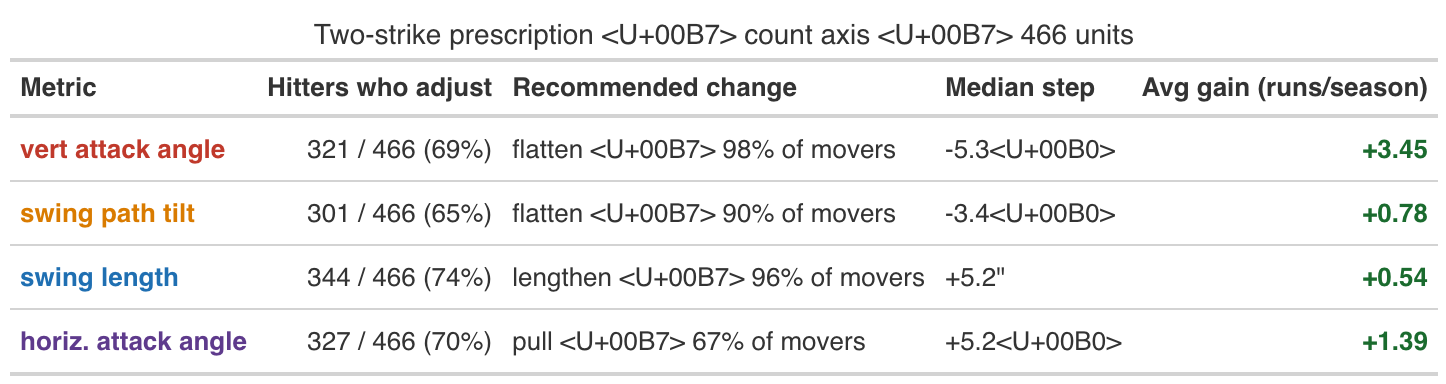

In [2]:
LEVER_ORDER  <- c("vert_attack_angle", "swing_path_tilt", "swing_length", "horz_attack_angle_pull")
LEVER_COLORS <- c(vert_attack_angle      = "#C0392B",
                  swing_path_tilt        = "#D97B00",
                  swing_length           = "#1F6FB2",
                  horz_attack_angle_pull = "#5E3A8C")
DIRECTION_LABEL <- list(
  vert_attack_angle      = c(pos = "steepen",  neg = "flatten"),
  swing_path_tilt        = c(pos = "steepen",  neg = "flatten"),
  swing_length           = c(pos = "lengthen", neg = "shorten"),
  horz_attack_angle_pull = c(pos = "pull",     neg = "oppo")
)

count_pb <- pb |> filter(axis == "count", lever %in% LEVER_ORDER)
movers   <- count_pb |> filter(step_sd != 0)
n_total  <- count_pb |> filter(lever == LEVER_ORDER[1]) |> nrow()

tbl <- map_dfr(LEVER_ORDER, function(lv) {
  r         <- movers |> filter(lever == lv)
  med       <- median(r$step_native, na.rm = TRUE)
  pct_neg   <- mean(r$step_sd < 0, na.rm = TRUE) * 100
  pct_pos   <- mean(r$step_sd > 0, na.rm = TRUE) * 100
  cons_pct  <- if (med < 0) pct_neg else pct_pos
  unit      <- if (lv == "swing_length") '"' else "°"
  direction <- if (med > 0) DIRECTION_LABEL[[lv]]["pos"] else DIRECTION_LABEL[[lv]]["neg"]
  tibble(
    metric      = str_replace_all(lv, "_", " ") |>
                    str_replace("horz attack angle pull", "horiz. attack angle"),
    adjusters   = sprintf("%d / %d  (%d%%)", nrow(r), n_total, round(nrow(r)/n_total*100)),
    recommended = sprintf("%s  ·  %d%% of movers", direction, round(cons_pct)),
    median_step = sprintf("%+.1f%s", med, unit),
    avg_gain    = mean(r$runs_gain, na.rm = TRUE),
    color       = LEVER_COLORS[[lv]]
  )
})

tbl_gt <- tbl |>
  mutate(avg_gain_fmt = sprintf("%+.2f", avg_gain)) |>
  gt() |>
  cols_label(
    metric       = "Metric",
    adjusters    = "Hitters who adjust",
    recommended  = "Recommended change",
    median_step  = "Median step",
    avg_gain_fmt = "Avg gain (runs/season)"
  ) |>
  cols_hide(columns = c(avg_gain, color)) |>
  tab_header(title = "Two-strike prescription  ·  count axis  ·  466 units") |>
  tab_options(
    table.font.names          = "sans-serif",
    table.font.size           = 13,
    column_labels.font.weight = "bold",
    heading.title.font.size   = 14,
    table.border.top.style    = "none"
  ) |>
  tab_style(
    style     = cell_text(color = "#1a6b2e", weight = "bold"),
    locations = cells_body(columns = avg_gain_fmt, rows = avg_gain >= 0)
  ) |>
  tab_style(
    style     = cell_text(color = "#9b1c1c", weight = "bold"),
    locations = cells_body(columns = avg_gain_fmt, rows = avg_gain < 0)
  )

for (i in seq_len(nrow(tbl))) {
  tbl_gt <- tbl_gt |>
    tab_style(
      style     = cell_text(color = tbl$color[i], weight = "bold"),
      locations = cells_body(columns = metric, rows = i)
    )
}

out <- plot_path("count_axis_consensus_table.png")
gtsave(tbl_gt, out)
cat(sprintf("Saved → %s\n", out))
IRdisplay::display_png(file = out)

Top 5 and bottom 5 by runs with their count-axis prescription for each lever.
Shows that the model says something concrete and different for each hitter.

In [3]:
count_wide <- pb |>
  filter(axis == "count", lever %in% LEVER_ORDER) |>
  pivot_wider(
    id_cols     = c(batter_id, batter_stand),
    names_from  = lever,
    values_from = c(step_native, runs_gain)
  )

hitters <- val |>
  inner_join(count_wide, by = c("batter_id","batter_stand")) |>
  drop_na(runs_total)

top5 <- hitters |> slice_max(runs_total, n = 5)
bot5 <- hitters |> slice_min(runs_total, n = 5)

fmt_step <- function(s, lv) {
  unit <- if (lv == "swing_length") '"' else "°"
  ifelse(is.na(s) | s == 0, "no change", sprintf("%+.1f%s", s, unit))
}
fmt_gain <- function(g) ifelse(is.na(g), "—", sprintf("%+.2f", g))

bind_rows(top5, bot5) |>
  transmute(
    Hitter        = label,
    `runs total`  = sprintf("%+.2f", runs_total),
    `VAA step`    = fmt_step(step_native_vert_attack_angle,      "vert_attack_angle"),
    `VAA gain`    = fmt_gain(runs_gain_vert_attack_angle),
    `Tilt step`   = fmt_step(step_native_swing_path_tilt,        "swing_path_tilt"),
    `Tilt gain`   = fmt_gain(runs_gain_swing_path_tilt),
    `Length step` = fmt_step(step_native_swing_length,           "swing_length"),
    `Length gain` = fmt_gain(runs_gain_swing_length),
    `HAA step`    = fmt_step(step_native_horz_attack_angle_pull, "horz_attack_angle_pull"),
    `HAA gain`    = fmt_gain(runs_gain_horz_attack_angle_pull)
  ) |>
  print(n = 10)

# A tibble: 10 x 10
   Hitter             `runs total` `VAA step` `VAA gain` `Tilt step` `Tilt gain`
   <chr>              <chr>        <chr>      <chr>      <chr>       <chr>      
 1 "Jos\u00e9 Caball~ +5.03        -5.3<U+00~ +4.87      -2.1<U+00B~ +0.24      
 2 "Nolan Arenado"    +4.68        -3.2<U+00~ +3.63      +3.4<U+00B~ +0.44      
 3 "Jose Altuve"      +3.46        +7.9<U+00~ +0.88      -3.4<U+00B~ +0.49      
 4 "Shohei Ohtani"    +3.33        -3.2<U+00~ +5.11      -5.1<U+00B~ +2.04      
 5 "Josh Lowe"        +3.09        -3.2<U+00~ +4.47      -2.1<U+00B~ +0.08      
 6 "Jarren Duran"     -2.80        -1.6<U+00~ +2.43      -2.1<U+00B~ +0.94      
 7 "Brandon Marsh"    -2.42        -3.2<U+00~ +2.93      -2.1<U+00B~ +0.83      
 8 "Bo Naylor"        -2.40        -5.3<U+00~ +4.13      -5.1<U+00B~ +1.24      
 9 "Yandy D\u00edaz"  -2.29        -5.3<U+00~ +4.94      -2.1<U+00B~ +0.17      
10 "Josh Naylor"      -2.25        -7.9<U+00~ +9.17      +1.0<U+00B~ -0.05      
# i 4 mo

## Summary printout — the three concrete league-level numbers

These are the numbers that belong in the abstract / conclusion.

In [4]:
cat("=== League-wide count-axis consensus (two-strike prescription) ===\n\n")

for (lv in LEVER_ORDER) {
  r         <- movers |> filter(lever == lv)
  n_tot     <- count_pb |> filter(lever == lv) |> nrow()
  pct_mov   <- nrow(r) / n_tot * 100
  pct_pos   <- mean(r$step_sd > 0, na.rm = TRUE) * 100
  pct_neg   <- 100 - pct_pos
  med       <- median(r$step_native, na.rm = TRUE)
  unit      <- if (lv == "swing_length") '"' else "°"
  mean_gain <- mean(r$runs_gain, na.rm = TRUE)
  direction <- if (pct_pos >= 50) "positive" else "negative"
  cons_pct  <- max(pct_pos, pct_neg)

  cat(sprintf("%-28s  %d%% of units move  %d%% %s  median %+.1f%s  mean gain %+.3f runs/season\n",
              lv, round(pct_mov), round(cons_pct), direction, med, unit, mean_gain))
}

=== League-wide count-axis consensus (two-strike prescription) ===

vert_attack_angle             69% of units move  98% negative  median -5.3<U+00B0>  mean gain +3.445 runs/season
swing_path_tilt               65% of units move  90% negative  median -3.4<U+00B0>  mean gain +0.780 runs/season
swing_length                  74% of units move  96% positive  median +5.2"  mean gain +0.545 runs/season
horz_attack_angle_pull        70% of units move  67% positive  median +5.2<U+00B0>  mean gain +1.386 runs/season
